In [1]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split

In [5]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Your project functions
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import (
    load_and_merge_csvs,
    clean_dataframe,
    prepare_rf_data
)

from src.evaluation import log_experiment

In [6]:
df = load_and_merge_csvs(
    data_dir="../data/CIC2017/",
    output_parquet="../data/raw/merged_raw.parquet"
)

print("Raw shape:", df.shape)

df = clean_dataframe(df)

print("Clean shape:", df.shape)

Loading fast merged raw data from Parquet...
Raw shape: (2830743, 79)
Clean shape: (2520798, 79)


In [7]:
df = clean_dataframe(df)

print("Shape after cleaning:", df.shape)
print("\nLabels:")
print(df["label"].value_counts())

Shape after cleaning: (2520798, 79)

Labels:
label
BENIGN                        2095057
DoS Hulk                       172846
DDoS                           128014
PortScan                        90694
DoS GoldenEye                   10286
FTP-Patator                      5931
DoS slowloris                    5385
DoS Slowhttptest                 5228
SSH-Patator                      3219
Bot                              1948
Web Attack � Brute Force         1470
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


In [8]:
X, y, label_encoder = prepare_rf_data(df)

In [9]:
class_counts = pd.Series(y).value_counts().sort_index()

for class_id, count in class_counts.items():
    print(f"{label_encoder.classes_[class_id]}: {count}")

Bot: 1948
DDoS: 128014
DoS GoldenEye: 10286
DoS Hulk: 172846
DoS Slowhttptest: 5228
DoS slowloris: 5385
FTP-Patator: 5931
Heartbleed: 11
Infiltration: 36
PortScan: 90694
SSH-Patator: 3219
Web Attack � Brute Force: 1470
Web Attack � Sql Injection: 21
Web Attack � XSS: 652


In [10]:
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nAttack classes:")
print(label_encoder.classes_)

X shape: (425741, 78)
y shape: (425741,)

Attack classes:
['Bot' 'DDoS' 'DoS GoldenEye' 'DoS Hulk' 'DoS Slowhttptest'
 'DoS slowloris' 'FTP-Patator' 'Heartbleed' 'Infiltration' 'PortScan'
 'SSH-Patator' 'Web Attack � Brute Force' 'Web Attack � Sql Injection'
 'Web Attack � XSS']


In [11]:
print("\nEncoded class distribution:")
print(pd.Series(y).value_counts().sort_index())


Encoded class distribution:
0       1948
1     128014
2      10286
3     172846
4       5228
5       5385
6       5931
7         11
8         36
9      90694
10      3219
11      1470
12        21
13       652
Name: count, dtype: int64


In [12]:
for i, label in enumerate(label_encoder.classes_):
    print(i, "→", label)

0 → Bot
1 → DDoS
2 → DoS GoldenEye
3 → DoS Hulk
4 → DoS Slowhttptest
5 → DoS slowloris
6 → FTP-Patator
7 → Heartbleed
8 → Infiltration
9 → PortScan
10 → SSH-Patator
11 → Web Attack � Brute Force
12 → Web Attack � Sql Injection
13 → Web Attack � XSS


In [13]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [14]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [15]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (298018, 78)
Validation: (63861, 78)
Test: (63862, 78)


In [16]:
print("Before SMOTE:")
print(pd.Series(y_train).value_counts().sort_index())

Before SMOTE:
0       1364
1      89609
2       7200
3     120992
4       3660
5       3769
6       4152
7          8
8         25
9      63486
10      2253
11      1029
12        15
13       456
Name: count, dtype: int64


In [ ]:
# from sklearn.preprocessing import StandardScaler

In [ ]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_val_scaled = scaler.transform(X_val)

In [54]:
smote = SMOTE(
    random_state=42,
    k_neighbors=3
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)


In [55]:
from imblearn.over_sampling import ADASYN

In [38]:
strategy={
    7:50,
    11 :2000,
    12:200,
13:2000
}

In [39]:
# adasyn = ADASYN(sampling_strategy=strategy,random_state=42)
# X_res, y_res = adasyn.fit_resample(X_train, y_train)

# print("After ADASYN:", np.bincount(y_res))

In [40]:

# print("Before ADASYN:", X_train.shape)
# print("After ADASYN: ", X_res.shape)

# print("\nClass distribution after ADASYN:")
# print(pd.Series(y_res).value_counts().sort_index())

In [41]:

print("Before SMOTE:", X_train.shape)
print("After SMOTE: ", X_train_smote.shape)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())



Before SMOTE: (298018, 78)
After SMOTE:  (1693888, 78)

Class distribution after SMOTE:
0     120992
1     120992
2     120992
3     120992
4     120992
5     120992
6     120992
7     120992
8     120992
9     120992
10    120992
11    120992
12    120992
13    120992
Name: count, dtype: int64


In [42]:
rf_model = RandomForestClassifier(
    n_estimators=200, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)

rf_model.fit(X_train_smote, y_train_smote)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [43]:
# rf_model = RandomForestClassifier(
#     n_estimators=200, 
#     class_weight='balanced', 
#     random_state=42, 
#     n_jobs=-1
# )

# rf_model.fit(X_res, y_res)

In [44]:
importances = rf_model.feature_importances_

In [45]:
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

C:\Users\HP\AppData\Local\Temp\ipykernel_11472\1755559445.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


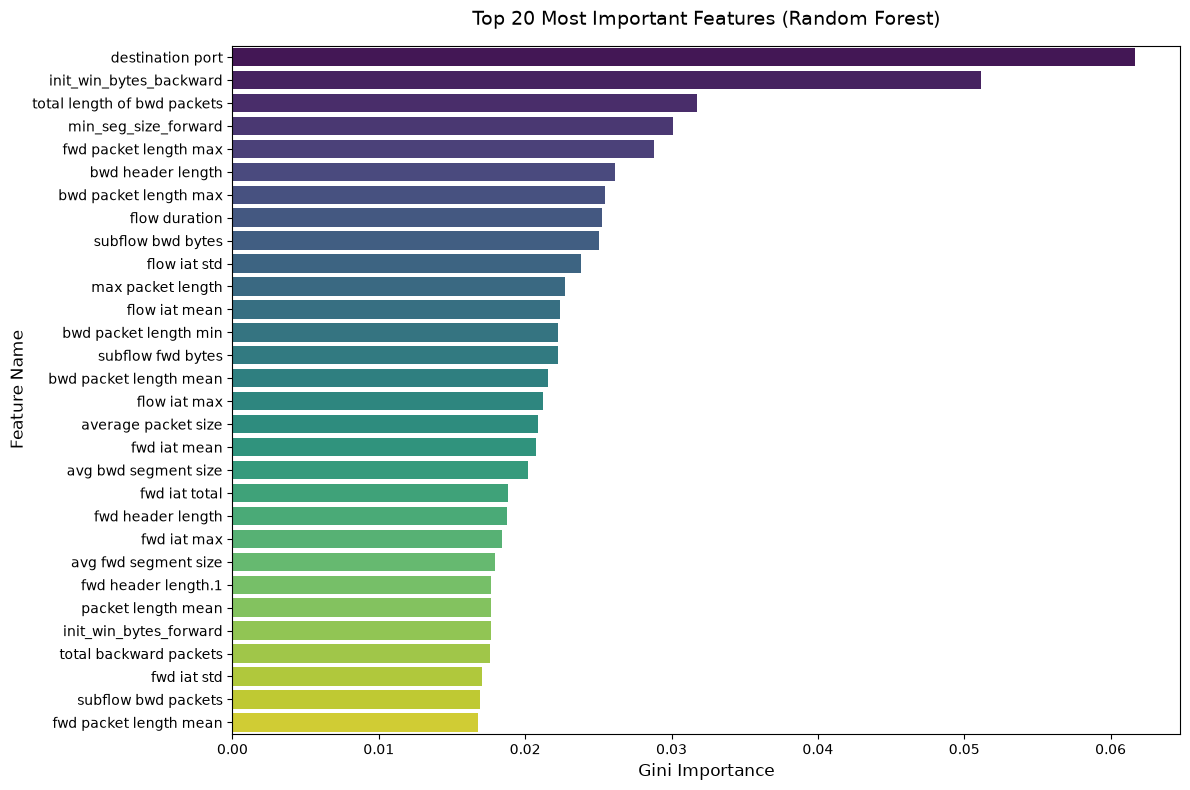


--- Bottom 10 Features (Candidates for Removal) ---
              Feature  Importance
        down/up ratio    0.003437
fwd packet length min    0.003205
       syn flag count    0.002004
        fwd psh flags    0.001881
       urg flag count    0.001682
             idle std    0.001079
       fin flag count    0.000409
           active std    0.000073
       rst flag count    0.000000
        bwd urg flags    0.000000
        bwd psh flags    0.000000
        fwd urg flags    0.000000
    bwd avg bulk rate    0.000000
 bwd avg packets/bulk    0.000000
   bwd avg bytes/bulk    0.000000
    fwd avg bulk rate    0.000000
 fwd avg packets/bulk    0.000000
   fwd avg bytes/bulk    0.000000
       cwe flag count    0.000000
       ece flag count    0.000000


In [46]:
# Sort the features from most to least important
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

# Display the Top 20 features
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Importance', 
    y='Feature', 
    data=feature_importance_df.head(30), 
    palette='viridis'
)
plt.title('Top 20 Most Important Features (Random Forest)', fontsize=14, pad=15)
plt.xlabel('Gini Importance', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

# Display the Bottom 10 features (the ones you will likely want to drop later)
print("\n--- Bottom 10 Features (Candidates for Removal) ---")
print(feature_importance_df.tail(20).to_string(index=False))

In [47]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import average_precision_score

y_val_pred_smote = rf_model.predict(X_val)
y_val_proba = rf_model.predict_proba(X_val)
classes = rf_model.classes_

val_accuracy = accuracy_score(y_val, y_val_pred_smote)
val_precision = precision_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)
val_recall = recall_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)
val_f1 = f1_score(
    y_val,
    y_val_pred_smote,
    average="macro",
    zero_division=0
)

# PR-AUC (one-vs-rest)
y_val_bin = label_binarize(y_val, classes=classes)
present = y_val_bin.sum(axis=0) > 0   # only classes present in y_val

val_pr_auc_macro = average_precision_score(
    y_val_bin[:, present], y_val_proba[:, present], average="macro"
)
val_pr_auc_weighted = average_precision_score(
    y_val_bin[:, present], y_val_proba[:, present], average="weighted"
)

print("RF-02 Validation Results")
print("-------------------------")
print(f"Accuracy:            {val_accuracy:.4f}")
print(f"Macro Precision:     {val_precision:.4f}")
print(f"Macro Recall:        {val_recall:.4f}")
print(f"Macro F1:            {val_f1:.4f}")
print(f"Macro PR-AUC:        {val_pr_auc_macro:.4f}")
print(f"Weighted PR-AUC:     {val_pr_auc_weighted:.4f}")

print("\nPer-class PR-AUC")
for i, c in enumerate(classes):
    if present[i]:
        print(f"{c}: {average_precision_score(y_val_bin[:, i], y_val_proba[:, i]):.4f}")

c:\Users\HP\miniconda3\envs\ai_net_env\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
c:\Users\HP\miniconda3\envs\ai_net_env\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


RF-02 Validation Results
-------------------------
Accuracy:            0.0215
Macro Precision:     0.0109
Macro Recall:        0.0752
Macro F1:            0.0056
Macro PR-AUC:        0.1147
Weighted PR-AUC:     0.3153

Per-class PR-AUC
0: 0.0143
1: 0.3544
2: 0.0836
3: 0.3414
4: 0.0509
5: 0.0350
6: 0.0139
7: 0.0044
8: 0.0002
9: 0.3060
10: 0.0542
11: 0.3438
12: 0.0000
13: 0.0030


In [48]:
print(
    classification_report(
        y_val,
        y_val_pred_smote,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

                            precision    recall  f1-score   support

                       Bot       0.00      0.00      0.00       292
                      DDoS       0.00      0.00      0.00     19202
             DoS GoldenEye       0.00      0.00      0.00      1543
                  DoS Hulk       0.15      0.05      0.08     25927
          DoS Slowhttptest       0.00      0.00      0.00       784
             DoS slowloris       0.00      0.00      0.00       808
               FTP-Patator       0.00      0.00      0.00       889
                Heartbleed       0.00      1.00      0.00         2
              Infiltration       0.00      0.00      0.00         6
                  PortScan       0.00      0.00      0.00     13604
               SSH-Patator       0.00      0.00      0.00       483
  Web Attack � Brute Force       0.00      0.00      0.00       220
Web Attack � Sql Injection       0.00      0.00      0.00         3
          Web Attack � XSS       0.00      0.00

In [49]:
y_test_pred_smote = rf_model.predict(X_test)

print("RF-02 Test Results")
print("------------------")

print(
    classification_report(
        y_test,
        y_test_pred_smote,
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

c:\Users\HP\miniconda3\envs\ai_net_env\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


RF-02 Test Results
------------------
                            precision    recall  f1-score   support

                       Bot       0.00      0.00      0.00       292
                      DDoS       0.00      0.00      0.00     19203
             DoS GoldenEye       0.00      0.00      0.00      1543
                  DoS Hulk       0.15      0.05      0.08     25927
          DoS Slowhttptest       0.00      0.00      0.00       784
             DoS slowloris       0.00      0.00      0.00       808
               FTP-Patator       0.00      0.00      0.00       890
                Heartbleed       0.00      1.00      0.00         1
              Infiltration       0.00      0.00      0.00         5
                  PortScan       0.00      0.00      0.00     13604
               SSH-Patator       0.00      0.00      0.00       483
  Web Attack � Brute Force       0.00      0.00      0.00       221
Web Attack � Sql Injection       0.00      0.00      0.00         3
         

In [50]:
test_accuracy = accuracy_score(y_test, y_test_pred_smote)

test_macro_precision = precision_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

test_macro_recall = recall_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred_smote,
    average="macro",
    zero_division=0
)

print(f"Accuracy:        {test_accuracy:.4f}")
print(f"Macro Precision: {test_macro_precision:.4f}")
print(f"Macro Recall:    {test_macro_recall:.4f}")
print(f"Macro F1:        {test_macro_f1:.4f}")

Accuracy:        0.0210
Macro Precision: 0.0107
Macro Recall:    0.0752
Macro F1:        0.0056


In [51]:
# cols_to_drop = [
#     'rst flag count', 'bwd urg flags', 'bwd psh flags', 'fwd urg flags',
#     'bwd avg bulk rate', 'bwd avg packets/bulk', 'bwd avg bytes/bulk',
#     'fwd avg bulk rate', 'fwd avg packets/bulk', 'fwd avg bytes/bulk',
#     'cwe flag count', 'ece flag count'
# ]
# X = X.drop(columns=cols_to_drop)

In [52]:
import numpy as np
from sklearn.metrics import classification_report

# 1. Get the raw predicted probabilities instead of the final predictions
probs = rf_model.predict_proba(X_test)

# 2. Use the exact integer indices from your label encoding
brute_force_idx = 11
sqli_idx = 12
xss_idx = 13

# 3. Create a weight multiplier array (default is 1.0 for all classes)
threshold_weights = np.ones(probs.shape[1])

# 4. Apply aggressive multipliers to the Web Attack classes. 
threshold_weights[sqli_idx] = 5.0        # Extreme boost for the rarest class
threshold_weights[xss_idx] = 3.0         # Heavy boost
threshold_weights[brute_force_idx] = 2.0 # Moderate boost

# 5. Multiply the raw probabilities by your custom weights
adjusted_probs = probs * threshold_weights

# 6. Make the final prediction based on the adjusted probabilities
y_pred_adjusted = np.argmax(adjusted_probs, axis=1)

# 7. Evaluate the new results (comparing integer targets to integer predictions)
print("Results AFTER Threshold Adjustment:")
print("-" * 40)
print(classification_report(y_test, y_pred_adjusted,target_names=label_encoder.classes_, zero_division=0))

c:\Users\HP\miniconda3\envs\ai_net_env\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Results AFTER Threshold Adjustment:
----------------------------------------
                            precision    recall  f1-score   support

                       Bot       0.00      0.00      0.00       292
                      DDoS       0.00      0.00      0.00     19203
             DoS GoldenEye       0.00      0.00      0.00      1543
                  DoS Hulk       0.14      0.05      0.07     25927
          DoS Slowhttptest       0.00      0.00      0.00       784
             DoS slowloris       0.00      0.00      0.00       808
               FTP-Patator       0.00      0.00      0.00       890
                Heartbleed       0.00      1.00      0.00         1
              Infiltration       0.00      0.00      0.00         5
                  PortScan       0.00      0.00      0.00     13604
               SSH-Patator       0.00      0.00      0.00       483
  Web Attack � Brute Force       0.38      0.90      0.54       221
Web Attack � Sql Injection       0.00 